In [30]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,List
from langchain_openai.chat_models import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
load_dotenv()


from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool

import requests
import random

# Table of contents 

1. Defining tools
2. Creating all the nodes
3. Building graphs

In [31]:
llm =  ChatOpenAI(model="gpt-4.1-mini")

# 1) Defining Tools 

In [32]:
search_tool =  DuckDuckGoSearchRun(region="us-en")



@tool
def get_weather_tool(city: str) -> str:
    """Get the current temperature of a city."""
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
    ).json()["results"][0]

    data = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": geo["latitude"], "longitude": geo["longitude"], "current_weather": True},
    ).json()

    return f"{data['current_weather']['temperature']} °C in {city}"



tools =  [search_tool,get_weather_tool]


llm_with_tools =  llm.bind_tools(tools)




# 2)  Creating all the nodes 

In [33]:
class Chat(TypedDict):
    
    messages : List[str]
    
    

def chat_node(state :  Chat):
    
    ans =  llm_with_tools.invoke(state["messages"])
    return {"messages":[ans] }


tool_node =  ToolNode(tools)

# 3)  Building graph 

In [34]:
graph =  StateGraph(Chat)

graph.add_node("chat_node",chat_node)
graph.add_node("tools",tool_node)

graph.add_edge(START,"chat_node")

graph.add_conditional_edges("chat_node",tools_condition)
graph.add_edge("tools",END)


workflow =  graph.compile()

In [35]:
ans1 = workflow.invoke({"messages":"get me the weather of mumbai city "})["messages"][-1].content

print(ans1)
ans2   =  workflow.invoke({"messages":"who is the capital of india ? "})["messages"][-1].content 
print(ans2)

33.3 °C in Mumbai
The capital of India is New Delhi.


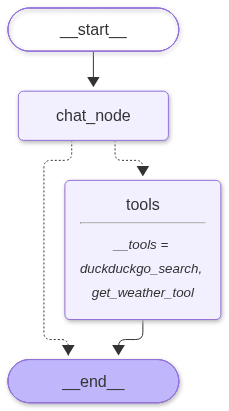

In [36]:

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())